<a href="https://colab.research.google.com/github/cpt0/data201-labs/blob/main/data201-Project1/PROJECT_three_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [31]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import mean_squared_error, roc_auc_score

from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold
)

from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, Normalizer, KBinsDiscretizer,
    FunctionTransformer
)

In [32]:
file_path = "/content/drive/MyDrive/DATA 201/Datasets/heart.csv"

heart = pd.read_csv(file_path)

heart.head()



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [33]:
heart["target"].value_counts()

,count
target,
1,526
0,499


In [34]:
heart.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


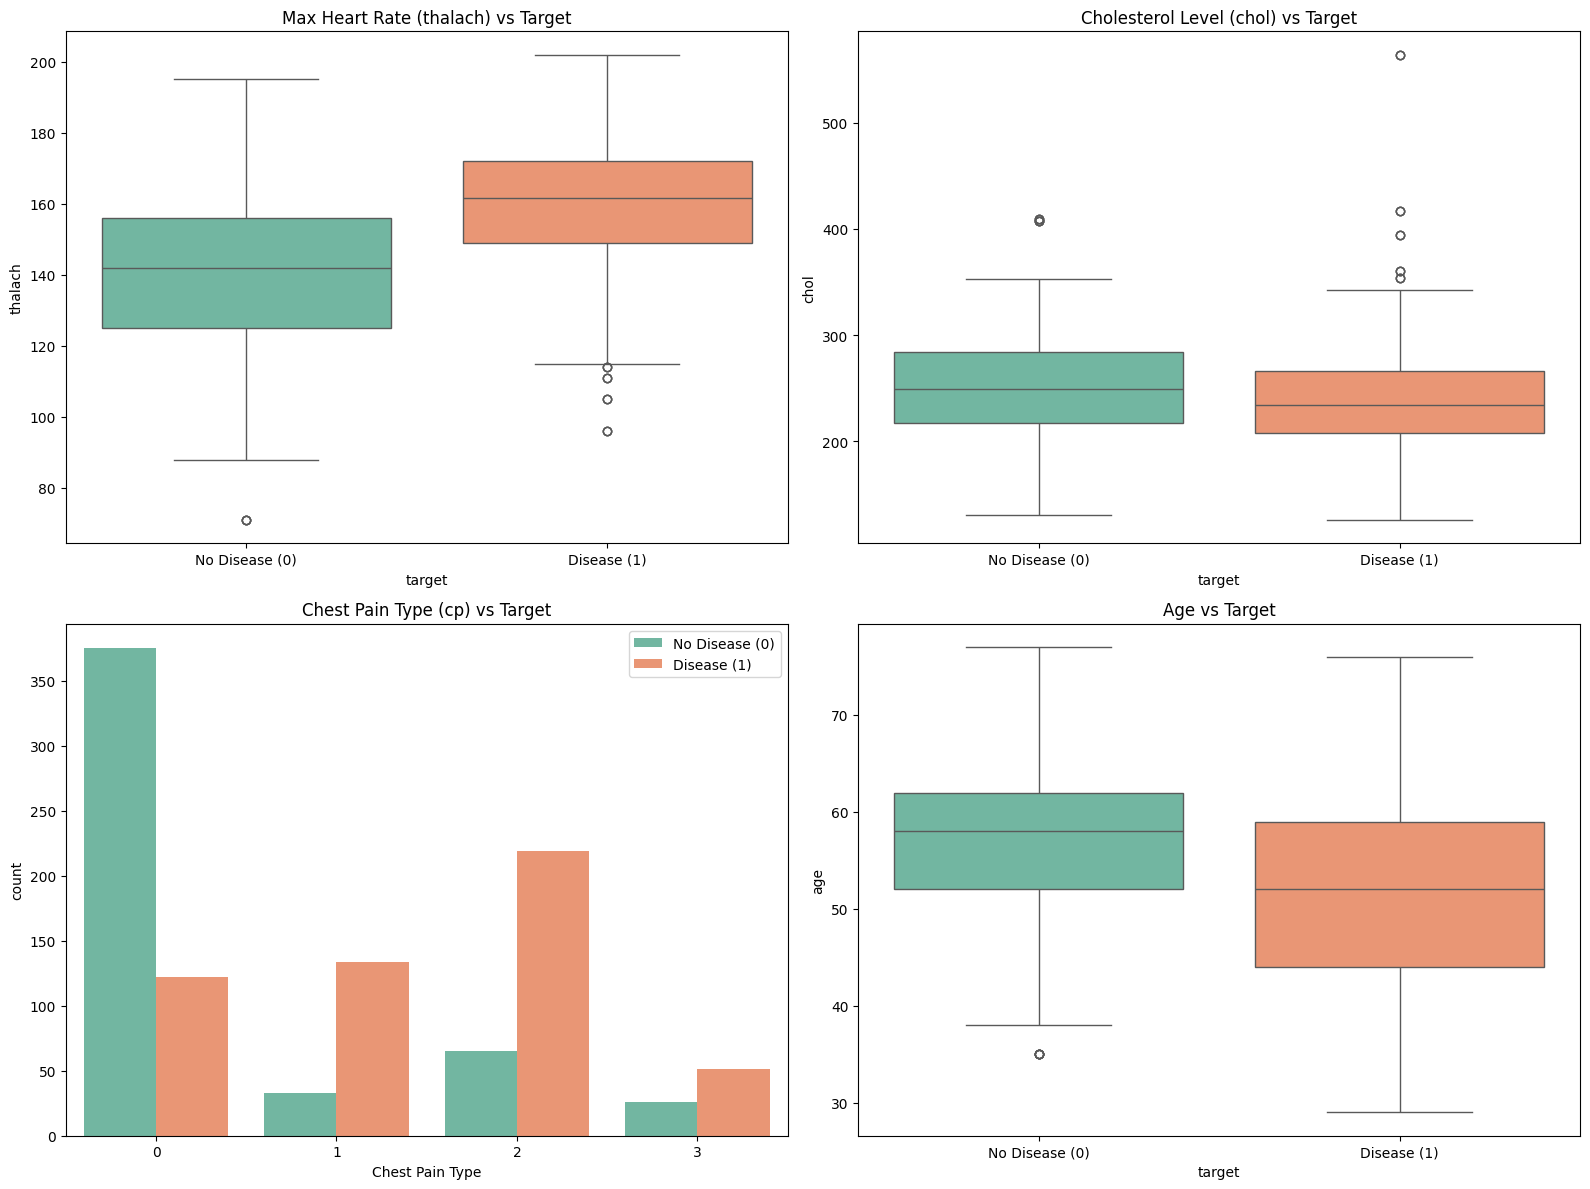

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Boxplot of Max Heart Rate (thalach) vs Target
sns.boxplot(ax=axes[0, 0], x='target', y='thalach', hue='target', data=heart, palette='Set2', legend=False)
axes[0, 0].set_title('Max Heart Rate (thalach) vs Target')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(['No Disease (0)', 'Disease (1)'])

# 2. Boxplot of Cholesterol (chol) vs Target
sns.boxplot(ax=axes[0, 1], x='target', y='chol', hue='target', data=heart, palette='Set2', legend=False)
axes[0, 1].set_title('Cholesterol Level (chol) vs Target')
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(['No Disease (0)', 'Disease (1)'])

# 3. Count plot of Chest Pain Type (cp) grouped by Target
sns.countplot(ax=axes[1, 0], x='cp', hue='target', data=heart, palette='Set2')
axes[1, 0].set_title('Chest Pain Type (cp) vs Target')
axes[1, 0].set_xlabel('Chest Pain Type')
axes[1, 0].legend(['No Disease (0)', 'Disease (1)'])

# 4. Boxplot of Age vs Target
sns.boxplot(ax=axes[1, 1], x='target', y='age', hue='target', data=heart, palette='Set2', legend=False)
axes[1, 1].set_title('Age vs Target')
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['No Disease (0)', 'Disease (1)'])

plt.tight_layout()
plt.show()

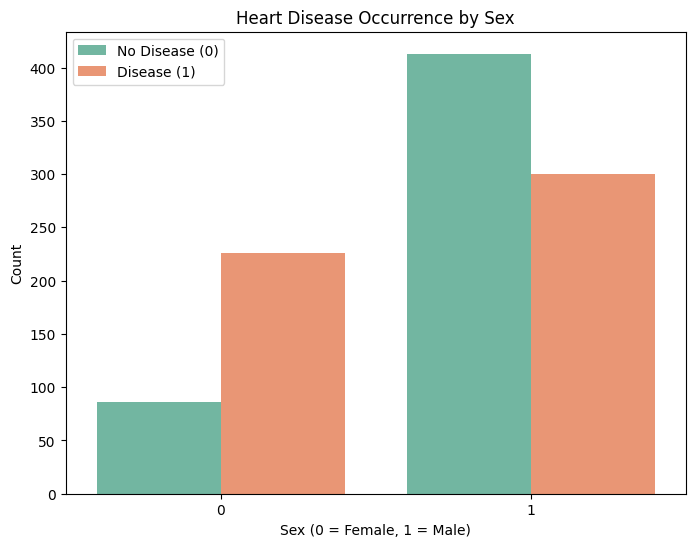

In [153]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.countplot(x='sex', hue='target', data=heart, palette='Set2')
plt.title('Heart Disease Occurrence by Sex')
plt.xlabel('Sex (0 = Female, 1 = Male)')
plt.ylabel('Count')
plt.legend(['No Disease (0)', 'Disease (1)'])
plt.show()

**PART 1**

1. What does each row of your dataset represent? What is your response variable? What are its possible classes?

What each row represents is a patient the response variable is the target which is whether or not they have heart disease which is shown by 1s and 0s.


2. Select the predictors you believe could be useful for classification.
age, sex, thalach, cp. Based on the graphs above due to the different variation between no disease and disease.


3. Examine the distribution of your response variable.
 How many observations belong to each class?
 Using value.counts() we can see that
 526 belong to yes/1
 499 belong to no/0
 Is the dataset reasonably balanced or imbalanced?
 It is balanced

4. Define a false positive and false negative in the context of your dataset.

False Positive
It predicts they have heart disease but they don't

False Negative
It predicts that they don't have heart disease and they do

5. Which type of error would you be more concerned about in this application, or are they
similarly important? Explain your reasoning.

False Negative would be worse, because it would say that someone doesn't have heart disease but they actually do so they might not get treatment which could be fatal.

The reason this isn't as bad as a false positive is becasue although there is panic, the extra testing would show that the patient is safe.

In [8]:
heart[['age', 'sex', 'cp', 'thalach', 'oldpeak', 'ca', 'exang', 'slope','thal']].describe()

,age,sex,cp,thalach,oldpeak,ca,exang,slope,thal
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,149.114146,1.071512,0.754146,0.336585,1.385366,2.323902
std,9.072290,0.460373,1.029641,23.005724,1.175053,1.030798,0.472772,0.617755,0.620660
min,29.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,132.000000,0.000000,0.000000,0.000000,1.000000,2.000000
50%,56.000000,1.000000,1.000000,152.000000,0.800000,0.000000,0.000000,1.000000,2.000000
75%,61.000000,1.000000,2.000000,166.000000,1.800000,1.000000,1.000000,2.000000,3.000000
max,77.000000,1.000000,3.000000,202.000000,6.200000,4.000000,1.000000,2.000000,3.000000


**Part 2**

1. Investigate your features and predictors.


2. Determine whether your dataset contains missing values. If it does, explain how you
handled them.
So we used isna().sum as we as the sum of that same function. And we saw there were no na's meaning there wasn't much to do. However thal had 0's

3. Determine whether any categorical predictors need to be encoded before modeling.
There was no need for encoding.

4. Divide the data, then use k-fold CV on training data.


5. Determine whether predictors should be standardized for any of the classifiers you will
use.
Yes it was needed for age and thalach.

In [9]:
heart.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [10]:
encoded_heart = pd.get_dummies(heart, columns=['cp'], drop_first=False, dtype=int)
print(encoded_heart)

      age  sex  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0      52    1       125   212    0        1      168      0      1.0      2   
1      53    1       140   203    1        0      155      1      3.1      0   
2      70    1       145   174    0        1      125      1      2.6      0   
3      61    1       148   203    0        1      161      0      0.0      2   
4      62    0       138   294    1        1      106      0      1.9      1   
...   ...  ...       ...   ...  ...      ...      ...    ...      ...    ...   
1020   59    1       140   221    0        1      164      1      0.0      2   
1021   60    1       125   258    0        0      141      1      2.8      1   
1022   47    1       110   275    0        0      118      1      1.0      1   
1023   50    0       110   254    0        0      159      0      0.0      2   
1024   54    1       120   188    0        1      113      0      1.4      1   

      ca  thal  target  cp_0  cp_1  cp_

In [154]:
X = encoded_heart[["age","thalach","cp_0","cp_1","cp_2","cp_3","sex"]]
y = encoded_heart["target"]

In [155]:
# Split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25, #this is the default %, you can remove this line if you want to
    random_state=99,

)

In [156]:
# Build preprocessing steps
preprocess = make_pipeline(
    StandardScaler()
)

# Combine preprocessing with logistic regression
def pipeline(classification_model):
  pipe = make_pipeline(
      preprocess,
      classification_model
  )
  return pipe

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=4
)

# KNN without scaling
def cross_validation(classification_model):
  scores = cross_val_score(
      classification_model,
      X_train,
      y_train,
      cv=cv,
      scoring="accuracy"
  )
  return scores.mean()

In [157]:
cross_validation(LogisticRegression(max_iter=2000))

np.float64(0.7539173245055598)

In [158]:
cross_validation(LinearDiscriminantAnalysis())

np.float64(0.7565147271029624)

In [159]:
cross_validation(QuadraticDiscriminantAnalysis(reg_param=0.01))

np.float64(0.7657074951192598)

In [166]:

knn = make_pipeline(
    StandardScaler(),
      KNeighborsClassifier()
)

knn_grid = {
    'kneighborsclassifier__n_neighbors': [51, 53, 55, 57, 59],
    'kneighborsclassifier__weights': ['uniform','distance']
}

grid_knn = GridSearchCV(
    knn,
    knn_grid,
    cv=5,
    scoring='roc_auc',
    return_train_score=False
)

grid_knn.fit(X_train, y_train)

print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC and AUC:", round(grid_knn.best_score_, 4))

KNN best parameters: {'kneighborsclassifier__n_neighbors': 51, 'kneighborsclassifier__weights': 'distance'}
KNN best CV ROC and AUC: 0.9966


In [167]:

  k_values = [51, 53, 55, 57, 59]

#create an empty list
  cv_scores = []

#Run cross-validation
for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,

    )

    cv_scores.append(scores.mean())

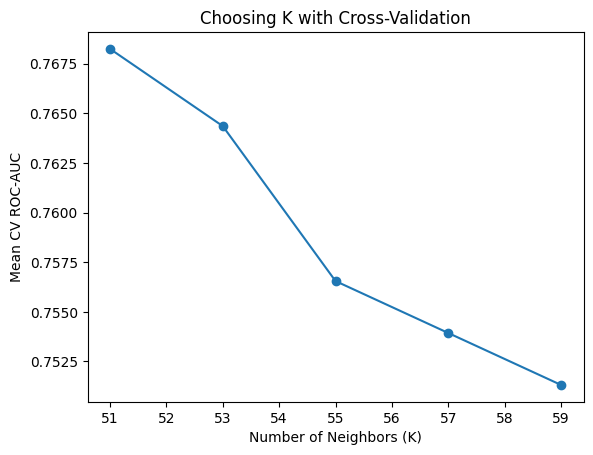

In [168]:
plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV ROC-AUC")
plt.title("Choosing K with Cross-Validation")

plt.show()

Based on the graph the best K-Value is 51, with the highest accuracy

In [134]:
from sklearn.metrics import accuracy_score

best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=51)
)

best_knn.fit(X_train, y_train)
best_knn_pred = best_knn.predict(X_test)
accuracy_score(y_test, best_knn_pred)



0.7859922178988327

Based on the cross validation scores KNN would work the best when k = 51.

In [169]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


knn_cm = confusion_matrix(y_test, best_knn_pred)
print(knn_cm)

TN_knn, FP_knn, FN_knn, TP_knn = knn_cm.ravel()

print(f"\nMetrics:")
print(f"(TN): {TN_knn}")
print(f"(FP): {FP_knn}")
print(f" (FN): {FN_knn}")
print(f"(TP): {TP_knn}")


accuracy = accuracy_score(
    y_test_labels,
    pred_50_labels
)

precision = precision_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

recall = recall_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)



[[ 94  34]
 [ 21 108]]

Metrics:
(TN): 94
(FP): 34
 (FN): 21
(TP): 108
Accuracy: 0.7821011673151751
Precision: 0.7517241379310344
Recall: 0.8449612403100775
Specificity: 0.8046875
F1: 0.7956204379562044


LOGISTIC

In [24]:
# Week 3, Part 4: fit the model
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression()

logreg.fit(X_train, y_train)

LogisticRegression()

In [25]:
# Predicted probability of heart disease (target = 1)
logreg_prob = logreg.predict_proba(X_test)[:, 1]

# Predicted class using the default 0.50 threshold
pred_50 = (logreg_prob >= 0.50).astype(int)

pred_50 = logreg.predict(X_test)

In [27]:
# Week 3: table comparing the results
results = X_test.copy()

results["Actual"] = y_test.values
results["P(Disease)"] = logreg_prob
results["Prediction_0.50"] = pred_50

results.head(15)

,age,thalach,cp_0,cp_1,cp_2,cp_3,fbs,sex,Actual,P(Disease),Prediction_0.50
383,58,111,1,0,0,0,0,1,0,0.064924,0
776,61,146,1,0,0,0,0,0,0,0.495243,0
792,68,141,1,0,0,0,1,1,0,0.074339,0
131,51,149,0,0,1,0,0,0,1,0.931446,1
464,67,160,0,0,1,0,0,0,1,0.904166,1
588,61,146,1,0,0,0,0,0,0,0.495243,0
734,52,156,1,0,0,0,1,1,0,0.196889,0
840,70,125,1,0,0,0,0,1,0,0.058700,0
456,47,152,0,0,1,0,0,1,0,0.750525,1
933,38,182,0,0,0,1,0,1,0,0.883049,1


In [140]:
from sklearn.metrics import confusion_matrix

confusion_matrix(
    results["Actual"],
    results["Prediction_0.50"])

array([[ 92,  36],
       [ 20, 109]])

In [141]:
import numpy as np

# Correctly reference the column inside the 'results' DataFrame
pred_50_labels = np.where(
    results["Prediction_0.50"] >= 0.50,
    "Yes",
    "No"
)


y_test_labels = np.where(y_test == 1, "Yes", "No")

# Confusion Matrix
logreg_cm = confusion_matrix(
    y_test_labels,
    pred_50_labels,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(logreg_cm)

TN, FP, FN, TP = logreg_cm.ravel()

print("\nMetrics:")
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

Confusion Matrix:
[[ 92  36]
 [ 20 109]]

Metrics:
TN: 92
FP: 36
FN: 20
TP: 109


In [142]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score)

accuracy = accuracy_score(
    y_test_labels,
    pred_50_labels
)

precision = precision_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

recall = recall_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    pred_50_labels,
    pos_label="Yes"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.7821011673151751
Precision: 0.7517241379310344
Recall: 0.8449612403100775
Specificity: 0.71875
F1: 0.7956204379562044


LDA

In [143]:
#Create model
lda = LinearDiscriminantAnalysis()

#Fit the model
lda.fit(X_train, y_train)

#Make prediction
lda_pred = lda.predict(X_test)

In [144]:
from sklearn.metrics import confusion_matrix

print("lda accuracy:", accuracy_score(y_test, lda_pred))
print("lda confusion matrix:")
print(confusion_matrix(y_test, lda_pred, labels=[0, 1]))

lda accuracy: 0.77431906614786
lda confusion matrix:
[[ 93  35]
 [ 23 106]]


In [146]:

lda_prob = lda.predict_proba(X_test)[:, 1]

lda_50_labels = np.where(
    lda_prob >= 0.50,
    "Yes",
    "No"
)

y_test_labels = np.where(y_test == 1, "Yes", "No")

# Confusion Matrix
lda_cm = confusion_matrix(
    y_test_labels,
    lda_50_labels,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(lda_cm)

TN, FP, FN, TP = lda_cm.ravel()

print("\nMetrics:")
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

Confusion Matrix:
[[ 93  35]
 [ 23 106]]

Metrics:
TN: 93
FP: 35
FN: 23
TP: 106


In [147]:
accuracy = accuracy_score(
    y_test_labels,
    lda_50_labels
)

precision = precision_score(
    y_test_labels,
    lda_50_labels,
    pos_label="Yes"
)

recall = recall_score(
    y_test_labels,
    lda_50_labels,
    pos_label="Yes"
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    lda_50_labels,
    pos_label="Yes"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.77431906614786
Precision: 0.75177304964539
Recall: 0.8217054263565892
Specificity: 0.7265625
F1: 0.7851851851851852


QDA

In [148]:
#Create model
qda = QuadraticDiscriminantAnalysis(reg_param=0.01)

#Fit the model
qda.fit(X_train, y_train)

#Make prediction
qda_pred = qda.predict(X_test)

In [149]:
print("qda accuracy:", accuracy_score(y_test, qda_pred))
print("qda confusion matrix:")
print(confusion_matrix(y_test, qda_pred, labels=[0, 1]))

qda accuracy: 0.8132295719844358
qda confusion matrix:
[[103  25]
 [ 23 106]]


In [150]:
qda_prob = qda.predict_proba(X_test)[:, 1]

qda_50_labels = np.where(
    qda_prob >= 0.50,
    "Yes",
    "No"
)

y_test_labels = np.where(y_test == 1, "Yes", "No")

# Confusion Matrix
qda_cm = confusion_matrix(
    y_test_labels,
    qda_50_labels,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(qda_cm)

TN, FP, FN, TP = qda_cm.ravel()

print("\nMetrics:")
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

Confusion Matrix:
[[103  25]
 [ 23 106]]

Metrics:
TN: 103
FP: 25
FN: 23
TP: 106


In [73]:
accuracy = accuracy_score(
    y_test_labels,
    qda_50_labels
)

precision = precision_score(
    y_test_labels,
    qda_50_labels,
    pos_label="Yes"
)

recall = recall_score(
    y_test_labels,
    qda_50_labels,
    pos_label="Yes"
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test_labels,
    qda_50_labels,
    pos_label="Yes"
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)

Accuracy: 0.7859922178988327
Precision: 0.8557692307692307
Recall: 0.689922480620155
Specificity: 0.7265625
F1: 0.7639484978540773


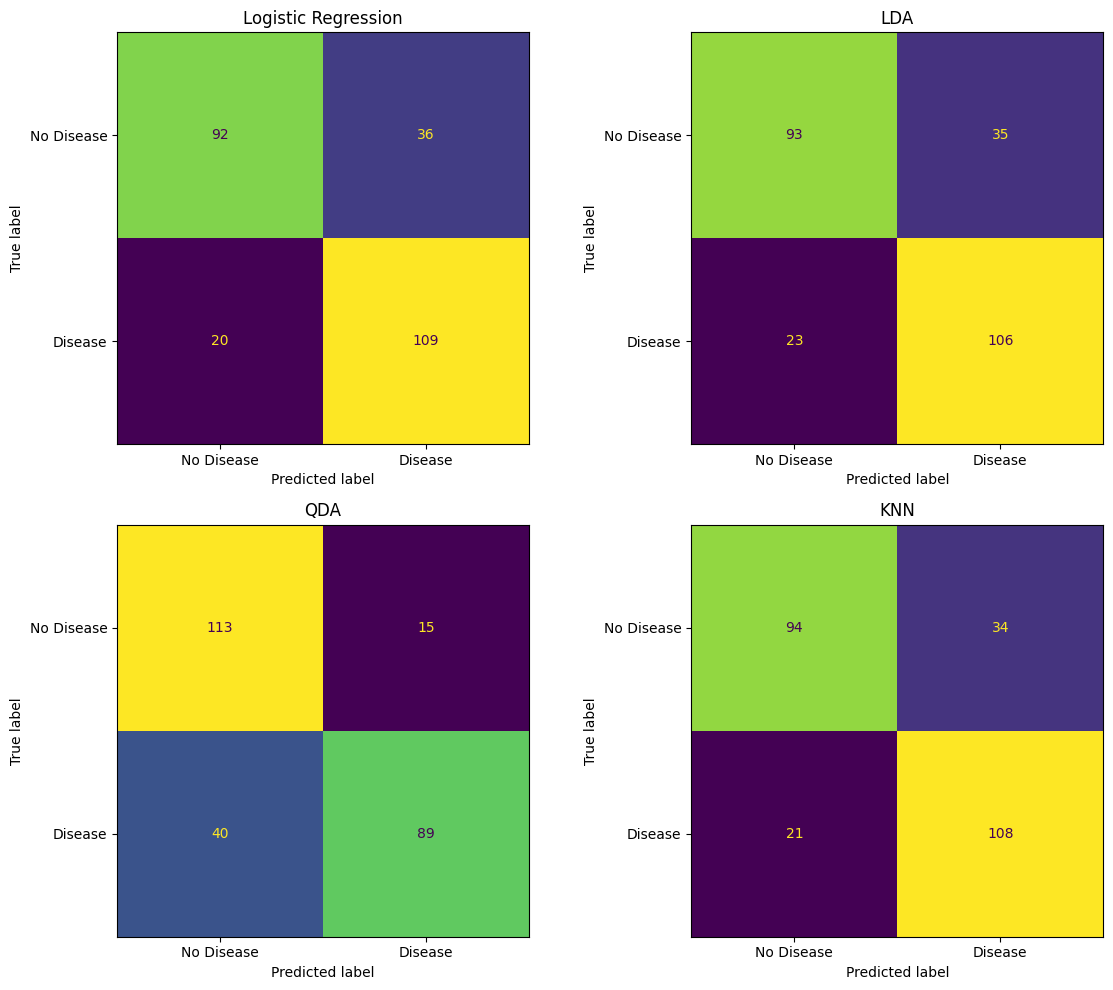

In [151]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, probabilities) in zip(
    axes.ravel(), model_probabilities.items()
):
    predictions = (probabilities >= 0.50).astype(int)

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Disease", "Disease"]
    )

    display_cm.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

# The QDA confusion matrix is actually TN: 103 FP: 25 FN: 23 TP: 106


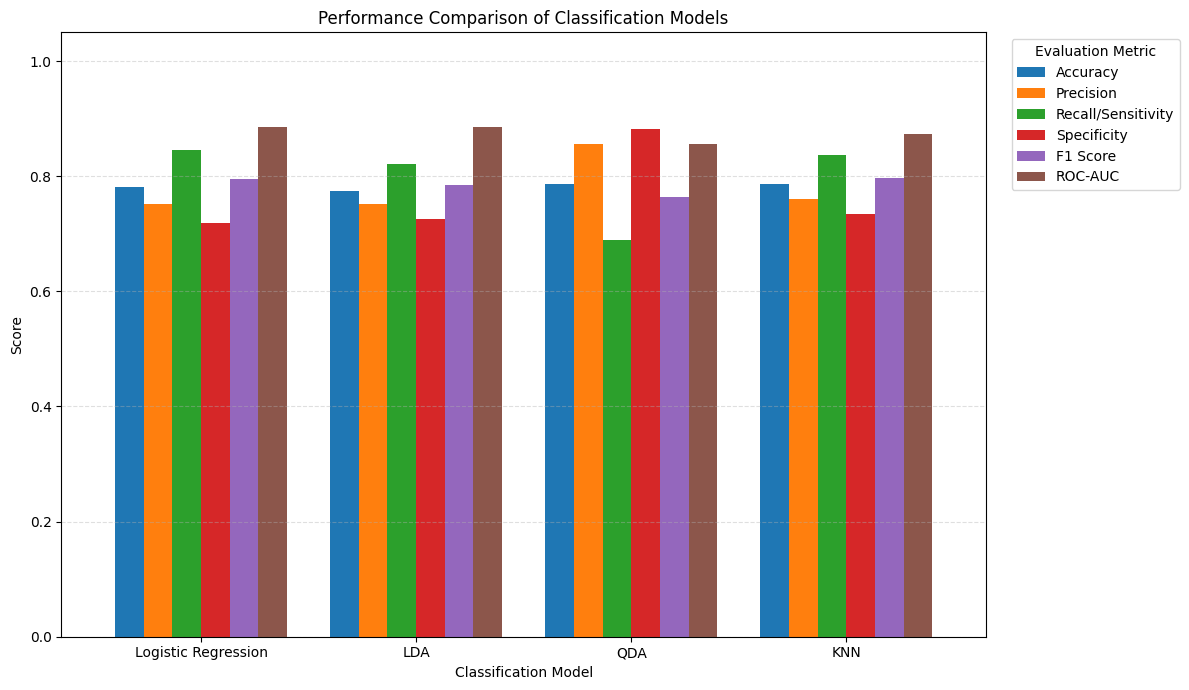

In [66]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert the existing model results into a DataFrame
comparison = pd.DataFrame(results_list).set_index("Model")

# Create a grouped bar chart comparing all six metrics
ax = comparison.plot(
    kind="bar",
    figsize=(12, 7),
    width=0.8
)

plt.title("Performance Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(
    title="Evaluation Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


Part 5 Reflect:
So based on the Accuracy Precision Recall Specificity and F1 scores, as well as the least amount of False Positives we get, KNN looks like the best model, when K=59. Now a close second is LDA with only one more false negative than KNN. I chose to have only a 50% threshold for both LDA, and Logistic Regression because of the severity of getting something wrong. Although, the recall for the KNN seems to be the lowest out of all of the models, which is important because recall helps find those false negative.

Part 6

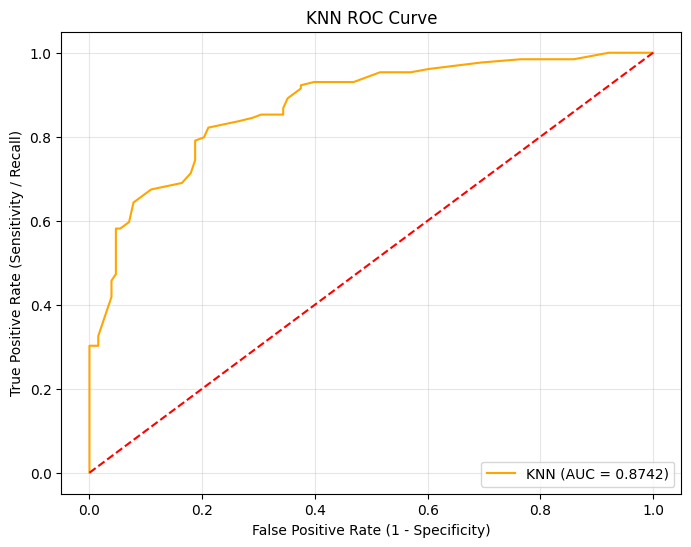

In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# --- 3. KNN ROC Curve ---
# Get prediction probabilities for the tuned KNN model
knn_prob = best_knn.predict_proba(X_test)[:, 1]

# Calculate the ROC curve and AUC score using the original numeric y_test and KNN probabilities
fpr_knn, tpr_knn, thresholds_knn = roc_curve(y_test, knn_prob)
auc_score_knn = roc_auc_score(y_test, knn_prob)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_knn,
    tpr_knn,
    color="orange",
    label=f"KNN (AUC = {auc_score_knn:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("KNN ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

In [65]:
# KNN
knn_prob = best_knn.predict_proba(X_test)[:, 1]
auc_knn = roc_auc_score(y_test, knn_prob)
print("KNN AUC:", auc_knn)

KNN AUC: 0.8702156007751938


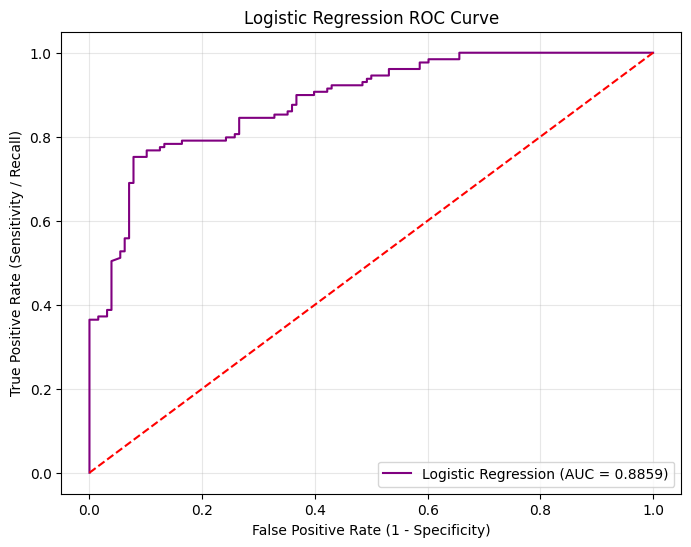

In [59]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# --- 2. Logistic Regression ROC Curve ---
# Calculate the ROC curve and AUC score using the original numeric y_test and Logistic Regression probabilities
fpr_log, tpr_log, thresholds_log = roc_curve(y_test, logreg_prob)
auc_score_log = roc_auc_score(y_test, logreg_prob)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_log,
    tpr_log,
    color="purple",
    label=f"Logistic Regression (AUC = {auc_score_log:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("Logistic Regression ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

In [60]:
# Logistic Regression
auc_logreg = roc_auc_score(y_test, logreg_prob)
print("Logistic Regression AUC:", auc_logreg)

Logistic Regression AUC: 0.8859011627906976


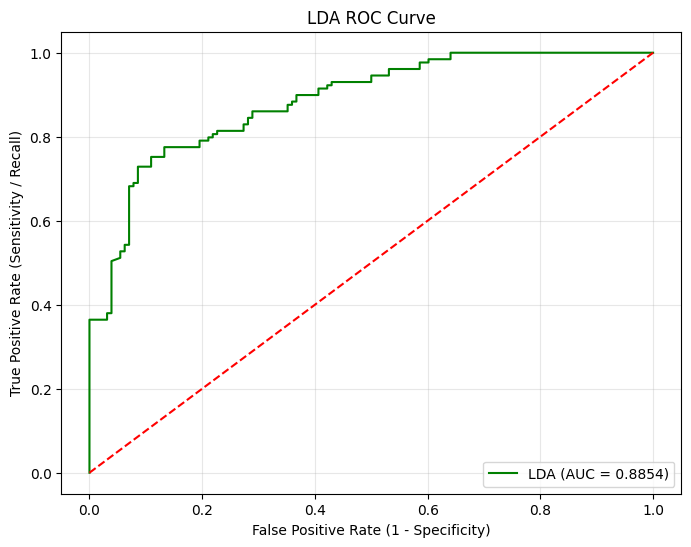

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# --- 1. LDA ROC Curve ---
# Calculate the ROC curve and AUC score using the original numeric y_test and LDA probabilities
fpr_lda, tpr_lda, thresholds_lda = roc_curve(y_test, lda_prob)
auc_score_lda = roc_auc_score(y_test, lda_prob)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_lda,
    tpr_lda,
    color="green",
    label=f"LDA (AUC = {auc_score_lda:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("LDA ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

In [63]:
# LDA
auc_lda = roc_auc_score(y_test, lda_prob)
print("LDA AUC:", auc_lda)

LDA AUC: 0.8596778100775193


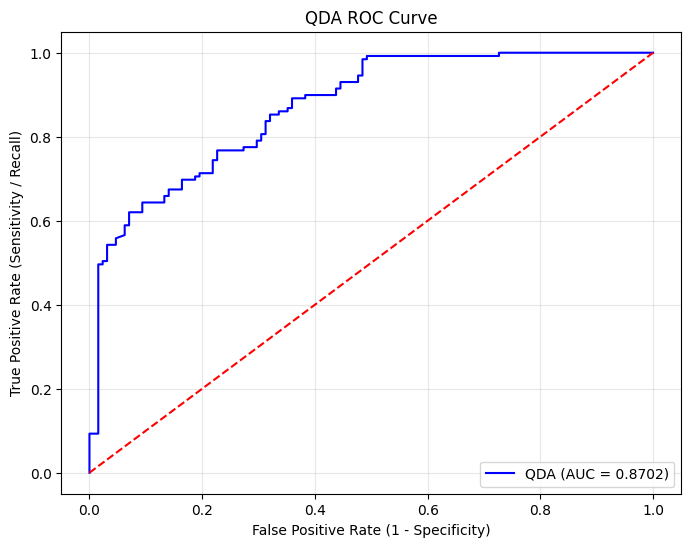

In [60]:


# 1. Use the pre-calculated QDA probabilities we obtained earlier
# qda_prob represents predict_proba(X_test)[:, 1]

# 2. Calculate the ROC curve and AUC score using the original numeric y_test
fpr, tpr, thresholds = roc_curve(y_test, qda_prob)
auc_score = roc_auc_score(y_test, qda_prob)

# 3. Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    color="blue",
    label=f"QDA (AUC = {auc_score:.4f})"
)

# Plot the reference diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("QDA ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.show()

In [64]:
# QDA
auc_qda = roc_auc_score(y_test, qda_prob)
print("QDA AUC:", auc_qda)

QDA AUC: 0.8702156007751938


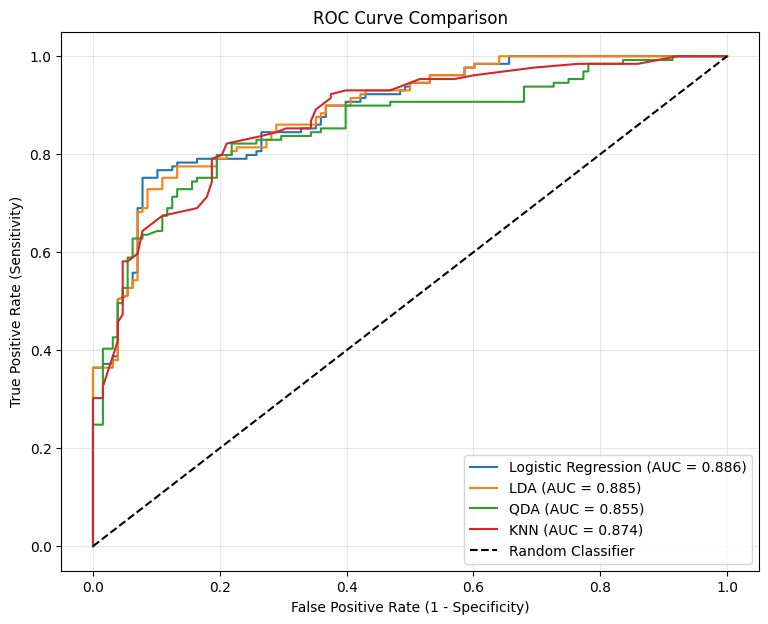

In [63]:

model_probabilities = {
    "Logistic Regression": logreg.predict_proba(X_test)[:, 1],
    "LDA": lda.predict_proba(X_test)[:, 1],
    "QDA": qda.predict_proba(X_test)[:, 1],
    "KNN": best_knn.predict_proba(X_test)[:, 1]
}
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

for name, probabilities in model_probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


Logistic Regression has the highest AUC with 0.886, so it would seem likely that Logistic regression does the best out of all the models.

Part 7:
Comparing the performace of all the models we can very much see that they all work pretty well and can stand on their own. What edges out mostly is the Logistic Regression model with the best AUC score out of all of the models. Not only does Logistic Regression have the fewest amount of False Negatives with only 20, it also has a very high recall score which is very important for these type of testing that has to deal with health.

A limitation that I had with my model was that there was an assumption right from the start that there might have been some duplicate models, and that might've changed up how the data looked. A part from that the dataset was actually pretty well cleaned up and there wasn't any need for encoding or changing any varibles, although cp was something that might've needed to be changed I didn't because it didn't seem as necessary.

Some additional information that would've been very helpful is knowing if the cells were duplicated or not. Because that would obviously change how the models work and it would change the values that we get as well as changing the threshold. Another thing that would be important would to know other predictors such as if they had heart attacks in the past, I remember many past datasets in past classes had that type of predictor, so that might've given more insight and might've given the models a better predictor to test on.